<div style="font-family: 'Segoe UI', sans-serif; box-sizing: border-box;">
  <div style="background: #0f1923; border-radius: 14px; padding: 40px 50px; color: #e8edf2; position: relative; overflow: hidden;">
    <div style="position: absolute; top: 0; right: 0; width: 320px; height: 100%; opacity: 0.07; pointer-events: none;">
    </div>
    <div style="display: inline-block; width: fit-content; background: rgba(29,158,117,0.18); border: 1px solid rgba(93,202,165,0.35); border-radius: 6px; padding: 3px 12px; margin-bottom: 18px;">
      <span style="font-size: 11px; letter-spacing: 2px; text-transform: uppercase; color: #5DCAA5; font-weight: 500;">Tutorial</span>
    </div>
    <h1 style="margin: 0 0 6px 0; font-size: 2.5em; font-weight: 700; letter-spacing: -0.5px; color: #e8edf2; line-height: 1.15;">
      Getting Started with <span style="color: #5DCAA5;">Finesse 3</span>
    </h1>
    <p style="margin: 0 0 4px 0; font-size: 1.05em; color: rgba(232,237,242,0.55); font-weight: 300; letter-spacing: 0.5px;">
      Interferometer simulation for optical physics
    </p>
    <div style="border-top: 1px solid rgba(93,202,165,0.2); margin: 22px 0 18px;"></div>
    <div style="display: flex; justify-content: space-between; align-items: flex-end; flex-wrap: wrap; gap: 12px;">
      <div style="display: flex; gap: 28px; flex-wrap: wrap;">
        <div>
          <p style="margin: 0 0 2px; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Authors</p>
          <p style="margin: 0; font-size: 0.95em; color: rgba(232,237,242,0.85);">Katie Gray</p>
        </div>
        <div>
          <p style="margin: 0 0 2px; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Version</p>
          <p style="margin: 0; font-size: 0.95em; color: rgba(232,237,242,0.85);">Finesse 3.x · Python</p>
        </div>
        <div>
          <p style="margin: 0 0 2px; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Docs & Install</p>
          <a href="https://finesse.ifosim.org/docs/latest/install/first.html#i-am-a-python-user-and-have-anaconda-conda-installed-already-windows-osx-or-linux" style="margin: 0; font-size: 0.95em; color: #5DCAA5; text-decoration: none;">finesse.ifosim.org ↗</a>
        </div>
      </div>
      <div>
        <p style="margin: 0; font-size: 0.9em; color: rgba(232,237,242,0.4); font-weight: 300;">April 17, 2026</p>
      </div>
    </div>
  </div>
  <div style="margin-top: 14px; background: #0f1923; border-radius: 10px; padding: 18px 28px; display: flex; gap: 32px; flex-wrap: wrap;">
    <div style="display: flex; align-items: center; gap: 10px;">
      <div style="width: 8px; height: 8px; border-radius: 50%; background: #5DCAA5;"></div>
      <span style="font-size: 13px; color: rgba(232,237,242,0.6);">Build optical models with <code style="background: rgba(93,202,165,0.15); color: #5DCAA5; padding: 1px 6px; border-radius: 4px; font-size: 12px;">finesse</code></span>
    </div>
    <div style="display: flex; align-items: center; gap: 10px;">
      <div style="width: 8px; height: 8px; border-radius: 50%; background: #1D9E75;"></div>
      <span style="font-size: 13px; color: rgba(232,237,242,0.6);">Simulate cavities, mirrors, beamsplitters</span>
    </div>
    <div style="display: flex; align-items: center; gap: 10px;">
      <div style="width: 8px; height: 8px; border-radius: 50%; background: #0F6E56;"></div>
      <span style="font-size: 13px; color: rgba(232,237,242,0.6);">Analyse transfer functions &amp; noise</span>
    </div>
  </div>
</div>

In [13]:
# Imports 
import finesse
import numpy as np
import matplotlib.pyplot as plt

<div style="font-family: 'Segoe UI', sans-serif; box-sizing: border-box; max-width: 100%; overflow: hidden;">
  <div style="background: #0f1923; border-radius: 14px; padding: 32px 42px; color: #e8edf2; box-sizing: border-box; max-width: 100%;">
    <div style="display: inline-block; width: fit-content; background: rgba(29,158,117,0.18); border: 1px solid rgba(93,202,165,0.35); border-radius: 6px; padding: 3px 12px; margin-bottom: 18px;">
      <span style="font-size: 11px; letter-spacing: 2px; text-transform: uppercase; color: #5DCAA5; font-weight: 500;">Section 1 — Setup</span>
    </div>
    <h2 style="margin: 0 0 8px 0; font-size: 1.8em; font-weight: 700; color: #e8edf2; line-height: 1.2;">
      Beam Propagation &amp; Profile Modelling
    </h2>
    <p style="margin: 0 0 20px 0; font-size: 1.0em; color: rgba(232,237,242,0.5); font-weight: 300;">
      Using <span style="color: #5DCAA5;">Finesse 3</span> · KatScript 
    </p>
    <div style="border-top: 1px solid rgba(93,202,165,0.15); margin-bottom: 20px;"></div>
    <p style="margin: 0 0 14px 0; font-size: 0.95em; color: rgba(232,237,242,0.8); line-height: 1.7;">
      This section models how a Gaussian laser beam propagates through a sequence of optical elements — 
      a lens, a flat steering mirror, and a photodetector — using Finesse 3's built-in beam propagation tools. 
      The beam is described by its <strong style="color: #5DCAA5;">complex beam parameter</strong> <em>q</em>, 
      which encodes both the beam waist size <em>w₀</em> and the wavefront radius of curvature <em>R_c</em> at any point along the path.
    </p>
    <p style="margin: 0 0 20px 0; font-size: 0.95em; color: rgba(232,237,242,0.8); line-height: 1.7;">
      From a beam profile, the waist location can be determined (and if using a Phasics camera, the wavefront curvature as well) which are fed into the input beam parameter. As long as the right distances, radii of curvature, beamsplitter ratios and and lens focal lengths are specified, Finesse will parse the model and output a plot- no effort required!
    </p>
    <div style="display: flex; gap: 12px; flex-wrap: wrap; margin-bottom: 4px;">
      <div style="flex: 1; min-width: 160px; background: rgba(93,202,165,0.07); border: 1px solid rgba(93,202,165,0.2); border-radius: 8px; padding: 14px 18px;">
        <p style="margin: 0 0 4px; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Beam parameters</p>
        <p style="margin: 0; font-size: 0.88em; color: rgba(232,237,242,0.8); line-height: 1.6;">
          Input <em>q</em> from Phasics SID4 measurement.<br>
          <code style="background: rgba(93,202,165,0.12); color: #5DCAA5; padding: 1px 5px; border-radius: 3px; font-size: 11px;">w = 0.396 mm, Rc = −709 mm</code>
        </p>
      </div>
      <div style="flex: 1; min-width: 160px; background: rgba(93,202,165,0.07); border: 1px solid rgba(93,202,165,0.2); border-radius: 8px; padding: 14px 18px;">
        <p style="margin: 0 0 4px; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Optical path</p>
        <p style="margin: 0; font-size: 0.88em; color: rgba(232,237,242,0.8); line-height: 1.6;">
          input → L3 (f = 389 mm) → R5 (flat, 45°) → PD1 detector
        </p>
      </div>
      <div style="flex: 1; min-width: 160px; background: rgba(93,202,165,0.07); border: 1px solid rgba(93,202,165,0.2); border-radius: 8px; padding: 14px 18px;">
        <p style="margin: 0 0 4px; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">What's computed</p>
        <p style="margin: 0; font-size: 0.88em; color: rgba(232,237,242,0.8); line-height: 1.6;">
          Beam size at PD1, accumulated Gouy phase, propagation plot for design vs. as-built
        </p>
      </div>
    </div>
  </div>
</div>

q_in: w0=0.3315 mm, z=-211.7383 mm, w=0.3958 mm, Rc=-709.0915 mm


,z,w0,zr,w,RoC,S,Acc. Gouy,q
input.p1.i,0 m,331.52 um,324.51 mm,395.85 um,-709.09 mm,-1.4103 D,0°,-0.212 + 0.325j
input.p2.o,0 m,331.52 um,324.51 mm,395.85 um,-709.09 mm,-1.4103 D,0°,-0.212 + 0.325j
L3.p1.i,1 mm,331.52 um,324.51 mm,395.29 um,-710.45 mm,-1.4076 D,124.01m°,-0.211 + 0.325j
L3.p2.o,1 mm,189.12 um,105.6 mm,395.29 um,-251.37 mm,-3.9782 D,124.01m°,-0.194 + 0.106j
R5.p1.i,256.79 mm,189.12 um,105.6 mm,219.27 um,241.95 mm,4.133 D,91.942°,0.062 + 0.106j
R5.p2.o,256.79 mm,189.12 um,105.6 mm,219.27 um,241.95 mm,4.133 D,91.942°,0.062 + 0.106j
PD1_det.p1.i,348.19 mm,189.12 um,105.6 mm,333.46 um,226.08 mm,4.4232 D,116.99°,0.153 + 0.106j
PD1_det.p2.o,348.19 mm,189.12 um,105.6 mm,333.46 um,226.08 mm,4.4232 D,116.99°,0.153 + 0.106j


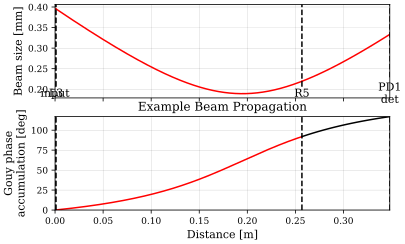

In [14]:
# Initialize a model 

PD1 = finesse.Model()

# Put optical path into this "parse" section

PD1.parse("""
# Input beam 
m input 0 1 0

# Free space from input to L3 lens is 0.001
s s_input_L3 input.p2 L3.p1 L=0.001

# L3: biconvex, f = +389mm
lens L3 0.389

# L3 -> R5:  255.79mm
s s_L3_R5 L3.p2 R5.p1 L=0.25579

# R5: flat mirror
m R5 1 0 0 -45

# R5 -> PD1: 91.4mm (reflected port = p3)
s s_R5_PD1_det R5.p2 PD1_det.p1 L=0.0914

# Photodetector-1 detector face
m PD1_det 0 1 0
""")


# Laser parameters 
lam = 1064e-9
w   = 0.7917e-3 / 2
Rc  = -709.0915e-3  #Rfoc = wavefront ROC, might have from a Phasics camera measurement)

# Propagate to get Gouy accumulation
q_in = finesse.BeamParam(w=w, Rc=Rc, wavelength=lam)
print("q_in: w0={:.4f} mm, z={:.4f} mm, w={:.4f} mm, Rc={:.4f} mm".format(
    q_in.w0*1e3, q_in.z*1e3, q_in.w*1e3, q_in.Rc*1e3))


PD1_design = PD1.propagate_beam('input.p1.i', 'PD1_det.p2.o', q_in=q_in)
PD1_design.print()

PD1_design.plot()
plt.title("Example Beam Propagation")
plt.show()

,z,w0,zr,w,RoC,S,Acc. Gouy,q
input.p1.i,0 m,331.52 um,324.51 mm,395.85 um,-709.09 mm,-1.4103 D,0°,-0.212 + 0.325j
input.p2.o,0 m,331.52 um,324.51 mm,395.85 um,-709.09 mm,-1.4103 D,0°,-0.212 + 0.325j
L1.p1.i,1 mm,331.52 um,324.51 mm,395.29 um,-710.45 mm,-1.4076 D,124.01m°,-0.211 + 0.325j
L1.p2.o,1 mm,252.74 um,188.6 mm,395.29 um,-383.64 mm,-2.6066 D,124.01m°,-0.227 + 0.189j
P1.p1.i,234.32 mm,252.74 um,188.6 mm,252.89 um,5.4727 m,182.73 mD,52.355°,0.007 + 0.189j
P1.p3.o,234.32 mm,252.74 um,188.6 mm,252.89 um,5.4727 m,182.73 mD,52.355°,0.007 + 0.189j
L2.p1.i,296.24 mm,252.74 um,188.6 mm,268.86 um,588.26 mm,1.6999 D,70.321°,0.068 + 0.189j
L2.p2.o,296.24 mm,268.8 um,213.33 mm,268.86 um,-10.138 m,-98.636 mD,70.321°,-0.004 + 0.213j
P2.p1.i,420.24 mm,268.8 um,213.33 mm,308.1 um,500.33 mm,1.9987 D,100.78°,0.120 + 0.213j
P2.p2.o,420.24 mm,268.8 um,213.33 mm,308.1 um,500.33 mm,1.9987 D,100.78°,0.120 + 0.213j


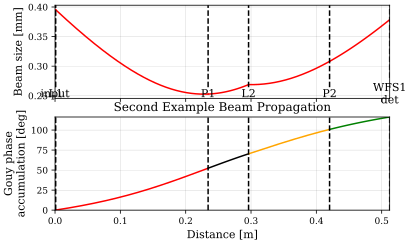

In [15]:
# A longer beampath example! 

WFS1 = finesse.Model()

WFS1.parse("""
# Input beam 
m input 0 1 0

# Free space from input to L1 lens 
s s_input_L1 input.p2 L1.p1 L=0.001

# L1: biconvex, f = +834mm
lens L1 0.834

# L1 -> P1: 233.32mm 
s s_L1_P1 L1.p2 P1.p1 L=0.23332

# P1: beamsplitter, 20% reflection, 80% transmission
bs P1 0.20 0.80 0 0

# P1 reflected port (p3) -> L2: 61.92mm 
s s_P1_L2 P1.p3 L2.p1 L=0.06192

# L2: plano-convex, f = +556mm
lens L2 0.556

# L2 -> P2: 124.00mm 
s s_L2_P2 L2.p2 P2.p1 L=0.12400

# P2: beamsplitter, 50% reflection, 50% transmission
bs P2 0.50 0.50 0 0

# P2 transmitted port (p2) -> WFS1: 92.00mm 
s s_P2_WFS1 P2.p2 WFS1_det.p1 L=0.09200

# WFS1 detector face 
m WFS1_det 0 1 0
""")

# Propagate to get Gouy accumulation

WFS1_design = WFS1.propagate_beam('input.p1.i', 'WFS1_det.p2.o', q_in=q_in)
WFS1_design.print()

WFS1_design.plot()
plt.title("Second Example Beam Propagation")
plt.show()

<div style="font-family: 'Segoe UI', sans-serif; box-sizing: border-box; max-width: 100%; overflow: hidden;">
  <div style="background: #0f1923; border-radius: 14px; padding: 32px 42px; color: #e8edf2; box-sizing: border-box; max-width: 100%;">
    <div style="display: inline-block; width: fit-content; background: rgba(29,158,117,0.18); border: 1px solid rgba(93,202,165,0.35); border-radius: 6px; padding: 3px 12px; margin-bottom: 18px;">
      <span style="font-size: 11px; letter-spacing: 2px; text-transform: uppercase; color: #5DCAA5; font-weight: 500;">Section 2 — Analysis</span>
    </div>
    <h2 style="margin: 0 0 8px 0; font-size: 1.8em; font-weight: 700; color: #e8edf2; line-height: 1.2;">
      Custom Plots &amp; Parameter Extraction
    </h2>
    <p style="margin: 0 0 20px 0; font-size: 1.0em; color: rgba(232,237,242,0.5); font-weight: 300;">
      Going beyond <code style="background: rgba(93,202,165,0.12); color: #5DCAA5; padding: 1px 6px; border-radius: 3px; font-size: 0.9em;">.plot()</code> · Design vs. As-Built overlay · Gouy &amp; beam size at arbitrary positions
    </p>
    <div style="border-top: 1px solid rgba(93,202,165,0.15); margin-bottom: 20px;"></div>
    <p style="margin: 0 0 14px 0; font-size: 0.95em; color: rgba(232,237,242,0.8); line-height: 1.7;">
      Finesse's native <code style="background: rgba(93,202,165,0.12); color: #5DCAA5; padding: 1px 5px; border-radius: 3px; font-size: 0.88em;">.plot()</code> method gives a quick sanity check, but for comparison plots or publication figures you need direct access to the underlying data. The trick is to call <code style="background: rgba(93,202,165,0.12); color: #5DCAA5; padding: 1px 5px; border-radius: 3px; font-size: 0.88em;">.plot()</code> on a throwaway figure, scrape the line data from its axes, then immediately close it — giving you clean <em>x/y</em> arrays to replot however you like.
    </p>
    <p style="margin: 0 0 20px 0; font-size: 0.95em; color: rgba(232,237,242,0.8); line-height: 1.7;">
      Finesse also adds vertical marker lines to its axes (one element boundary per component). These are distinguishable from real data lines because their <em>xdata</em> has only 2 points with a constant x — so a simple length filter strips them out before you concatenate across segments. Once you have the raw arrays, you can interpolate to any position, overlay design and as-built on the same axes, and annotate specific locations like the PD1 face with markers and reference lines.
    </p>
    <div style="display: flex; gap: 12px; flex-wrap: wrap; margin-bottom: 4px;">
      <div style="flex: 1; min-width: 150px; background: rgba(93,202,165,0.07); border: 1px solid rgba(93,202,165,0.2); border-radius: 8px; padding: 14px 18px;">
        <p style="margin: 0 0 6px; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Step 1</p>
        <p style="margin: 0 0 4px; font-size: 0.88em; color: #5DCAA5; font-weight: 500;">Scrape line data</p>
        <p style="margin: 0; font-size: 0.82em; color: rgba(232,237,242,0.65); line-height: 1.5;">Call <code style="background: rgba(93,202,165,0.12); color: #5DCAA5; padding: 0 4px; border-radius: 3px; font-size: 10px;">.plot()</code> into a throwaway fig, read <code style="background: rgba(93,202,165,0.12); color: #5DCAA5; padding: 0 4px; border-radius: 3px; font-size: 10px;">ax.get_lines()</code>, then <code style="background: rgba(93,202,165,0.12); color: #5DCAA5; padding: 0 4px; border-radius: 3px; font-size: 10px;">plt.close()</code></p>
      </div>
      <div style="flex: 1; min-width: 150px; background: rgba(93,202,165,0.07); border: 1px solid rgba(93,202,165,0.2); border-radius: 8px; padding: 14px 18px;">
        <p style="margin: 0 0 6px; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Step 2</p>
        <p style="margin: 0 0 4px; font-size: 0.88em; color: #5DCAA5; font-weight: 500;">Filter element markers</p>
        <p style="margin: 0; font-size: 0.82em; color: rgba(232,237,242,0.65); line-height: 1.5;">Keep only lines where <code style="background: rgba(93,202,165,0.12); color: #5DCAA5; padding: 0 4px; border-radius: 3px; font-size: 10px;">len(xdata) &gt; 2</code> — Finesse's boundary vlines have exactly 2 points</p>
      </div>
      <div style="flex: 1; min-width: 150px; background: rgba(93,202,165,0.07); border: 1px solid rgba(93,202,165,0.2); border-radius: 8px; padding: 14px 18px;">
        <p style="margin: 0 0 6px; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Step 3</p>
        <p style="margin: 0 0 4px; font-size: 0.88em; color: #5DCAA5; font-weight: 500;">Evaluate at any position</p>
        <p style="margin: 0; font-size: 0.82em; color: rgba(232,237,242,0.65); line-height: 1.5;">Concatenate segments, sort by z, then use <code style="background: rgba(93,202,165,0.12); color: #5DCAA5; padding: 0 4px; border-radius: 3px; font-size: 10px;">np.argmin(|z − z_target|)</code> to interpolate</p>
      </div>
      <div style="flex: 1; min-width: 150px; background: rgba(93,202,165,0.07); border: 1px solid rgba(93,202,165,0.2); border-radius: 8px; padding: 14px 18px;">
        <p style="margin: 0 0 6px; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Step 4</p>
        <p style="margin: 0 0 4px; font-size: 0.88em; color: #5DCAA5; font-weight: 500;">Overlay &amp; annotate</p>
        <p style="margin: 0; font-size: 0.82em; color: rgba(232,237,242,0.65); line-height: 1.5;">Plot both models on shared axes with <code style="background: rgba(93,202,165,0.12); color: #5DCAA5; padding: 0 4px; border-radius: 3px; font-size: 10px;">sharex=True</code>, add <code style="background: rgba(93,202,165,0.12); color: #5DCAA5; padding: 0 4px; border-radius: 3px; font-size: 10px;">axvline</code> + cross markers</p>
      </div>
    </div>
  </div>
</div>

Design PD1 position          : 348.2 mm
Model   beam radius @ PD1    : 0.3335 mm
As-built beam radius @ PD1   : 0.3335 mm
Model   Gouy @ PD1           : 116.99 (finesse units)
As-built Gouy @ PD1          : 117.02 (finesse units)


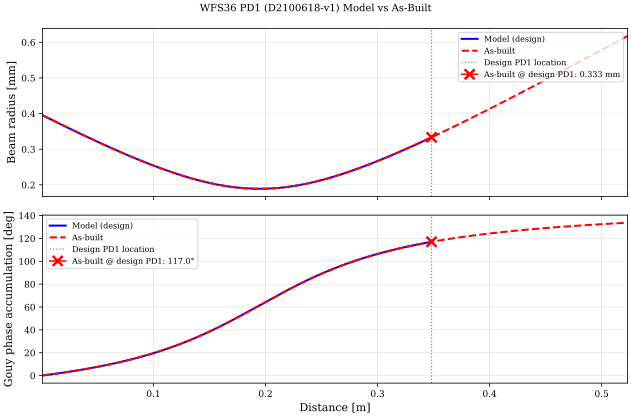

In [16]:
''' PD1 Comparison '''

import matplotlib.ticker as ticker
import numpy as np

# Build a second model with slightly different distances to compare with our model from the first section!

PD1 = finesse.Model()

PD1.parse("""
# Input beam 
m input 0 1 0

# Free space from input to L3 lens 
s s_input_L3 input.p2 L3.p1 L=0.001

# L3: biconvex, f = +389mm
lens L3 0.389

# L3 -> R5:  279mm
s s_L3_R5 L3.p2 R5.p1 L=0.279

# R5: flat mirror
m R5 1 0 0 -45

# R5 -> PD1: 243mm (reflected port = p3)
s s_R5_PD1_det R5.p2 PD1_det.p1 L=0.243

# PD1 detector face
m PD1_det 0 1 0
""")

PD1_built = PD1.propagate_beam('input.p1.i', 'PD1_det.p2.o', q_in=q_in)

# ── extract finesse's own smooth line data via throwaway figures ──
fig_m,  axs_m  = PD1_design.plot()
fig_ab, axs_ab = PD1_built.plot()

# beam size: first line only (skip finesse's element markers / vlines)
def get_main_lines(ax):
    """Return only data lines (not vlines added by finesse for element boundaries).
    Finesse element markers are vertical lines with xdata of length 2 and
    constant x — filter them out by checking if xdata has > 2 points."""
    return [l for l in ax.get_lines() if len(l.get_xdata()) > 2]

m_w_lines  = get_main_lines(axs_m[0])
m_g_lines  = get_main_lines(axs_m[1])
ab_w_lines = get_main_lines(axs_ab[0])
ab_g_lines = get_main_lines(axs_ab[1])

plt.close(fig_m)
plt.close(fig_ab)

# ── as-built value at model PD1 distance ──
z_pd1_model = list(PD1_design.node_info.values())[-1]['z']   # metres
z_end_ab    = list(PD1_built.node_info.values())[-1]['z']
q_end_ab    = list(PD1_built.node_info.values())[-1]['q']
dz          = z_pd1_model - z_end_ab                       # negative: model is shorter

q_at_pd1  = finesse.BeamParam(q=q_end_ab.q + dz, wavelength=lam)
w_at_pd1  = q_at_pd1.w * 1e3   # mm

# read Gouy at model PD1 from the as-built plotted data (finesse's own units)
ab_g_xdata = np.concatenate([l.get_xdata() for l in ab_g_lines])
ab_g_ydata = np.concatenate([l.get_ydata() for l in ab_g_lines])
sort_idx   = np.argsort(ab_g_xdata)
ab_g_xdata = ab_g_xdata[sort_idx]
ab_g_ydata = ab_g_ydata[sort_idx]
idx        = np.argmin(np.abs(ab_g_xdata - z_pd1_model))
gouy_at_pd1 = ab_g_ydata[idx]

# model values at its own PD1 for reference
m_g_xdata = np.concatenate([l.get_xdata() for l in m_g_lines])
m_g_ydata = np.concatenate([l.get_ydata() for l in m_g_lines])
m_w_xdata = np.concatenate([l.get_xdata() for l in m_w_lines])
m_w_ydata = np.concatenate([l.get_ydata() for l in m_w_lines])
m_gouy_at_pd1 = m_g_ydata[np.argmin(np.abs(m_g_xdata - z_pd1_model))]
m_w_at_pd1    = m_w_ydata[np.argmin(np.abs(m_w_xdata - z_pd1_model))] 

print(f"Design PD1 position          : {z_pd1_model*1e3:.1f} mm")
print(f"Model   beam radius @ PD1    : {m_w_at_pd1:.4f} mm")
print(f"As-built beam radius @ PD1   : {w_at_pd1:.4f} mm")
print(f"Model   Gouy @ PD1           : {m_gouy_at_pd1:.2f} (finesse units)")
print(f"As-built Gouy @ PD1          : {gouy_at_pd1:.2f} (finesse units)")

# ── build clean overlay plot ──
fig, (ax_w, ax_g) = plt.subplots(2, 1, sharex=True, figsize=(9, 6))

# beam size panel
for i, line in enumerate(m_w_lines):
    ax_w.plot(line.get_xdata(), line.get_ydata(),
              color='C0', lw=2, label='Model (design)' if i == 0 else '_nolegend_')
for i, line in enumerate(ab_w_lines):
    ax_w.plot(line.get_xdata(), line.get_ydata(),
              color='C1', lw=2, ls='--', label='As-built' if i == 0 else '_nolegend_')

ax_w.axvline(z_pd1_model, color='gray', ls=':', lw=1.2, label='Design PD1 location')
ax_w.plot(z_pd1_model, w_at_pd1, marker='x', color='C1',
          ms=10, mew=2.5,
          label=f'As-built @ design PD1: {w_at_pd1:.3f} mm')
ax_w.set_ylabel('Beam radius [mm]')
ax_w.legend(fontsize=8, loc='upper right')

# Gouy panel
for i, line in enumerate(m_g_lines):
    ax_g.plot(line.get_xdata(), line.get_ydata(),
              color='C0', lw=2, label='Model (design)' if i == 0 else '_nolegend_')
for i, line in enumerate(ab_g_lines):
    ax_g.plot(line.get_xdata(), line.get_ydata(),
              color='C1', lw=2, ls='--', label='As-built' if i == 0 else '_nolegend_')

ax_g.axvline(z_pd1_model, color='gray', ls=':', lw=1.2, label='Design PD1 location')
ax_g.plot(z_pd1_model, gouy_at_pd1, marker='x', color='C1',
          ms=10, mew=2.5,
          label=f'As-built @ design PD1: {gouy_at_pd1:.1f}°')
ax_g.set_ylabel('Gouy phase accumulation [deg]')
ax_g.set_xlabel('Distance [m]')
ax_g.legend(fontsize=8, loc='upper left')

fig.suptitle('WFS36 PD1 (D2100618-v1) Model vs As-Built')
plt.tight_layout()
plt.show()

<div style="font-family: 'Segoe UI', sans-serif; box-sizing: border-box; max-width: 100%; overflow: hidden;">
  <div style="background: #0f1923; border-radius: 14px; padding: 32px 42px; color: #e8edf2; box-sizing: border-box; max-width: 100%;">
    <div style="display: inline-block; width: fit-content; background: rgba(29,158,117,0.18); border: 1px solid rgba(93,202,165,0.35); border-radius: 6px; padding: 3px 12px; margin-bottom: 18px;">
      <span style="font-size: 11px; letter-spacing: 2px; text-transform: uppercase; color: #5DCAA5; font-weight: 500;">Section 3 — Cavity</span>
    </div>
    <h2 style="margin: 0 0 8px 0; font-size: 1.8em; font-weight: 700; color: #e8edf2; line-height: 1.2;">
      Modelling a Bow-Tie Cavity
    </h2>
    <p style="margin: 0 0 20px 0; font-size: 1.0em; color: rgba(232,237,242,0.5); font-weight: 300;">
      Output Mode Cleaner · LLO OMC · <code style="background: rgba(93,202,165,0.12); color: #5DCAA5; padding: 1px 6px; border-radius: 3px; font-size: 0.9em;">Xaxis</code> tuning sweep · power in reflection, circulation &amp; transmission
    </p>
    <div style="border-top: 1px solid rgba(93,202,165,0.15); margin-bottom: 20px;"></div>
    <p style="margin: 0 0 14px 0; font-size: 0.95em; color: rgba(232,237,242,0.8); line-height: 1.7;">
      For a linear cavity example that goes over multiple plots you can extract from such a setup, see the Finesse 3 documentation here: <a herf='https://finesse.ifosim.org/docs/latest/examples/hom/simple_cav.html'>Optical Cavities</a> 
    </p>
    <p style="margin: 0 0 14px 0; font-size: 0.95em; color: rgba(232,237,242,0.8); line-height: 1.7;">
      A <strong style="color: #5DCAA5;">bow-tie cavity</strong> is a four-mirror ring resonator where light circulates in a single direction, avoiding back-reflection into the input beam. The LLO Output Mode Cleaner (OMC) uses this geometry to filter the gravitational-wave readout beam, transmitting only the fundamental Gaussian mode and rejecting higher-order spatial modes and RF sidebands.
    </p>
    <p style="margin: 0 0 20px 0; font-size: 0.95em; color: rgba(232,237,242,0.8); line-height: 1.7;">
      In Finesse, a cavity is built by connecting <code style="background: rgba(93,202,165,0.12); color: #5DCAA5; padding: 1px 5px; border-radius: 3px; font-size: 0.88em;">bs</code> (beamsplitter) elements in a closed loop via <code style="background: rgba(93,202,165,0.12); color: #5DCAA5; padding: 1px 5px; border-radius: 3px; font-size: 0.88em;">s</code> (space) elements. Two flat couplers (OMC_1, OMC_2) handle input/output coupling via their transmission <em>T</em>, while two curved mirrors (OMC_3, OMC_4) provide mode stability via their radius of curvature <em>R_c</em>. Finesse automatically detects the closed loop and computes the round-trip field self-consistently. The <code style="background: rgba(93,202,165,0.12); color: #5DCAA5; padding: 1px 5px; border-radius: 3px; font-size: 0.88em;">Xaxis</code> action sweeps the tuning (longitudinal phase) of one mirror across a full free spectral range, mapping out where resonance occurs as a sharp peak in circulating and transmitted power — and a dip in reflection.
    </p>
    <div style="display: flex; gap: 12px; flex-wrap: wrap; margin-bottom: 4px;">
      <div style="flex: 1; min-width: 140px; background: rgba(93,202,165,0.07); border: 1px solid rgba(93,202,165,0.2); border-radius: 8px; padding: 14px 18px;">
        <p style="margin: 0 0 4px; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Topology</p>
        <p style="margin: 0 0 4px; font-size: 0.88em; color: #5DCAA5; font-weight: 500;">4-mirror bow-tie ring</p>
        <p style="margin: 0; font-size: 0.82em; color: rgba(232,237,242,0.65); line-height: 1.5;">2 flat couplers (T ≈ 0.76%), 2 curved mirrors (R_c ≈ 2.57 m), total round-trip length ≈ 1.13 m</p>
      </div>
      <div style="flex: 1; min-width: 140px; background: rgba(93,202,165,0.07); border: 1px solid rgba(93,202,165,0.2); border-radius: 8px; padding: 14px 18px;">
        <p style="margin: 0 0 4px; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Simulation</p>
        <p style="margin: 0 0 4px; font-size: 0.88em; color: #5DCAA5; font-weight: 500;">Xaxis tuning sweep</p>
        <p style="margin: 0; font-size: 0.82em; color: rgba(232,237,242,0.65); line-height: 1.5;">Sweep <code style="background: rgba(93,202,165,0.12); color: #5DCAA5; padding: 0 4px; border-radius: 3px; font-size: 10px;">OMC_2.phi</code> 0→360° in 1000 steps, log-scale output to resolve resonance lineshape</p>
      </div>
      <div style="flex: 1; min-width: 140px; background: rgba(93,202,165,0.07); border: 1px solid rgba(93,202,165,0.2); border-radius: 8px; padding: 14px 18px;">
        <p style="margin: 0 0 4px; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Readouts</p>
        <p style="margin: 0 0 4px; font-size: 0.88em; color: #5DCAA5; font-weight: 500;">3 photodiodes</p>
        <p style="margin: 0; font-size: 0.82em; color: rgba(232,237,242,0.65); line-height: 1.5;">Reflected (OMC_1.p2), circulating (OMC_1.p3), and transmitted (OMC_2.p3) power simultaneously</p>
      </div>
      <div style="flex: 1; min-width: 140px; background: rgba(93,202,165,0.07); border: 1px solid rgba(93,202,165,0.2); border-radius: 8px; padding: 14px 18px;">
        <p style="margin: 0 0 4px; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">What to look for</p>
        <p style="margin: 0 0 4px; font-size: 0.88em; color: #5DCAA5; font-weight: 500;">Resonance peak &amp; finesse</p>
        <p style="margin: 0; font-size: 0.82em; color: rgba(232,237,242,0.65); line-height: 1.5;">Sharp circulating power peak, reflection dip, and transmitted peak — width gives cavity finesse <em>F</em> ≈ π/(T+L)</p>
      </div>
    </div>
  </div>
</div>

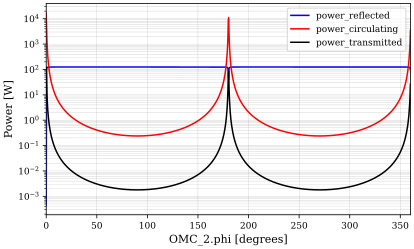

In [17]:
import finesse
from finesse.analysis.actions import Xaxis
finesse.init_plotting()

# parameters from https://finesse.docs.ligo.org/finesse-ligo/parameter_files/llo.html 

OMC_model = finesse.Model()
OMC_model.parse(
    """
    l l1 P=125                  # laser with P=125W
    s s1 l1.p1 OMC_1.p1 L=1     # space of 1m length connectint laser to OMC

    # Output Mode Cleaner (OMC) mirrors
    # Light transmitted through OMC_1 (from p1 to p3) enters OMC_2 (in p1 and is
    # reflected in p2). It continues into OMC_3 (enters in p1, reflected in p2).
    # Then it continues into OMC_4 (enters in p1, reflected in p2).
    # Finally it returns from OMC_4.p2 into OMC_1.p4, which reflects back into OMC_1.p3,
    # closing the bow tie cavity.
    bs OMC_1    T=0.0076    L=0     alpha=2.7609
    bs OMC_2    T=0.0075    L=0     alpha=2.7609
    bs OMC_3    T=36.0u     L=0     alpha=4.004     Rc=2.57321
    bs OMC_4    T=35.9u     L=0     alpha=4.004     Rc=2.57369

    # Connect spaces to form a bow tie
    s sOMC_1    OMC_1.p3    OMC_2.p1    L=0.2815 
    s sOMC_2    OMC_2.p2    OMC_3.p1    L=0.2842
    s sOMC_3    OMC_3.p2    OMC_4.p1    L=0.2815 
    s sOMC_4    OMC_4.p2    OMC_1.p4    L=0.2842

    # Photodiodes measuring the reflected, circulating, and transmitted light
    pd power_reflected      OMC_1.p2.o
    pd power_circulating    OMC_1.p3.o
    pd power_transmitted    OMC_2.p3.o
    """
)

# Change the tuning of mirror OMC_2 from 0 to 360 degrees
out = OMC_model.run(Xaxis('OMC_2.phi', 'lin', 0, 360, 1000))
out.plot(logy=True);